# Notebook 02: Robustness Evaluation under Image Degradation

## Research question
Notebook 01 demonstrated that all four no-leak inference modes
(ViT only / EBP only / Confidence-gated / LogReg fusion) score
nearly identically on clean CIFAKE (~95.4 - 95.8% accuracy with the current best_vit; the LogReg fusion collapses onto ViT since the EBP weight is ~0). This
notebook tests whether EBP becomes useful when test images are
**degraded** (JPEG compression, Gaussian noise, Gaussian blur,
downscale-upscale resampling).

## Hypothesis
**H1**: Under degradation, ViT confidence drops, opening a gap for EBP to
improve via confidence-gated or LogReg fusion.

**H0 (null)**: EBP carries no useful signal even under degradation;
all modes degrade together at the same rate.

## Method
1. Reload model + calibrators from Notebook 01 (no re-training).
2. For each (degradation_type, severity) configuration:
   a. Apply degradation to each test image pixel-space.
   b. Re-run ViT inference (model unchanged) and EBP score.
   c. Re-apply the four no-leak inference modes.
   d. Record accuracy + AUC + F1.
3. Plot Performance Degradation Curves per mode.
4. Optional secondary analysis: per-degradation calibration as upper bound.

## Reference
Hendrycks D & Dietterich T, 2019. "Benchmarking Neural Network
Robustness to Common Corruptions and Perturbations." ICLR.

In [1]:
# ============================================================
# CELL 1: INSTALL DEPENDENCIES
# ============================================================
# Same pinned versions as Notebook 01 so model loads without API
# mismatch.
!pip install -q \
    transformers==4.44.2 \
    datasets==2.21.0 \
    accelerate==0.33.0 \
    evaluate==0.4.3 \
    scikit-learn \
    tqdm pillow

print('[OK] Done. If running fresh, Runtime > Restart session, then Run All.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 73.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.3/527.3 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 315.1/315.1 kB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.6/177.6 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 63.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-contrib-python 4.13.0.92

In [1]:
# ============================================================
# CELL 2: IMPORTS + DRIVE MOUNT + THESIS_UTILS
# ============================================================
import warnings
warnings.filterwarnings('ignore')

import os, io, gc, random, itertools, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True

import cv2

from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report, f1_score,
    precision_recall_fscore_support, roc_auc_score, average_precision_score,
)

import torch
from torch.utils.data import Dataset as TorchDataset

from datasets import load_dataset
from transformers import (
    TrainingArguments, Trainer,
    ViTImageProcessor, ViTForImageClassification,
)
from torchvision.transforms import (
    Compose, Normalize, Resize, ToTensor,
)

import joblib

# --- Reproducibility ----
SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}  |  Seed: {SEED}')

# --- Mount Drive and load thesis_utils ----
from google.colab import drive
drive.mount('/content/drive')

import sys
THESIS_UTILS_DIR = '/content/drive/MyDrive/luanvan_thac_si'
if THESIS_UTILS_DIR not in sys.path:
    sys.path.append(THESIS_UTILS_DIR)

from thesis_utils import *
setup_thesis_style()

Device: cuda  |  Seed: 42
Mounted at /content/drive
[OK] Thesis matplotlib style activated (serif, savefig 300 dpi).


In [2]:
# ============================================================
# CELL 3: CONFIGURATION
# ============================================================
# Degradation grid -- follows the thesis design specification
# (Objective 2 in the research proposal and Chapter 1):
#   - JPEG QF in {90, 70, 50, 30}      -- lower = more lossy
#   - Gaussian noise sigma in {5, 10, 20, 30} on [0, 255] scale
#   - Gaussian blur kernel in {3, 5, 7} (odd, square)
#   - Downscale scale in {0.75, 0.5, 0.25} then upscale back to 224x224

CONFIG = {
    # Where Notebook 01 saved everything
    'artifacts_dir' : '/content/drive/MyDrive/luanvan_thac_si/notebook01_artifacts',
    'output_dir'    : '/content/outputs_nb02',
    'drive_backup'  : '/content/drive/MyDrive/luanvan_thac_si/notebook02_artifacts',

    # Class IDs (must match Notebook 01)
    'class_names'   : ['FAKE', 'REAL'],
    'fake_id'       : 0,
    'real_id'       : 1,

    # Dataset reconstruction -- must mirror Notebook 01 Cell 4-5 EXACTLY,
    # otherwise the test subset will differ and the robustness study
    # will compare apples to oranges. Notebook 01 pools train+test
    # (120k images), samples 4000 per class with default_rng(SEED),
    # then 70/15/15 stratified split.
    'hf_dataset_id' : 'dragonintelligence/CIFAKE-image-dataset',
    'n_per_class'   : 4000,            # 4000 FAKE + 4000 REAL = 8000 pool
    'train_ratio'   : 0.70,
    'val_ratio'     : 0.15,
    'test_ratio'    : 0.15,            # -> 1200 test images, 1200 val
    'image_size'    : 224,

    # Degradation grid
    'degradations'  : {
        'JPEG'      : {'param_name': 'QF',     'levels': [90, 70, 50, 30]},
        'Noise'     : {'param_name': 'sigma',  'levels': [5, 10, 20, 30]},
        'Blur'      : {'param_name': 'kernel', 'levels': [3, 5, 7]},
        'Downscale' : {'param_name': 'scale',  'levels': [0.75, 0.5, 0.25]},
    },

    # Eval batch size
    'eval_batch'    : 64,

    'seed'          : SEED,
}

FAKE_ID = CONFIG['fake_id']
REAL_ID = CONFIG['real_id']

os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(CONFIG['drive_backup'], exist_ok=True)

print('Config OK')
print(f'  Artifacts from N01: {CONFIG["artifacts_dir"]}')
print(f'  Outputs (this NB) : {CONFIG["output_dir"]}')

Config OK
  Artifacts from N01: /content/drive/MyDrive/luanvan_thac_si/notebook01_artifacts
  Outputs (this NB) : /content/outputs_nb02


In [3]:
# ============================================================
# CELL 4: LOAD ARTIFACTS FROM NOTEBOOK 01
# ============================================================
# We reload three things:
#   1. Fine-tuned ViT model + image processor
#   2. Calibration scalars: T_star, tau_star (numpy arrays in arrays.npz)
#   3. Fusion model: StandardScaler + LogisticRegression (joblib)
#
# After this cell, ViT is on GPU in eval mode, ready for re-inference
# on degraded images.

ckpt_path = os.path.join(CONFIG['artifacts_dir'], 'best_vit')
arrays_path = os.path.join(CONFIG['artifacts_dir'], 'arrays.npz')
fusion_path = os.path.join(CONFIG['artifacts_dir'], 'fusion_model.joblib')

assert os.path.exists(ckpt_path),   f'Missing model: {ckpt_path}'
assert os.path.exists(arrays_path), f'Missing arrays: {arrays_path}'
assert os.path.exists(fusion_path), f'Missing fusion model: {fusion_path}'

# --- 4.1 Model + processor ----
processor = ViTImageProcessor.from_pretrained(ckpt_path)
model     = ViTForImageClassification.from_pretrained(ckpt_path).to(DEVICE).eval()
print(f'[OK] Model loaded: {sum(p.numel() for p in model.parameters())/1e6:.1f}M params')

# Normalize + Resize transforms must match Notebook 01 exactly.
# Notebook 01 uses processor.size["height"] (which is 224 for ViT-Base/16).
img_mean = processor.image_mean
img_std  = processor.image_std
img_size = processor.size["height"]

clean_transform = Compose([
    Resize((img_size, img_size)),
    ToTensor(),
    Normalize(mean=img_mean, std=img_std),
])

# --- 4.2 Calibrators ----
arrs = np.load(arrays_path)
T_star    = float(arrs['T_star'])
tau_star  = float(arrs['tau_star'])
# Sanity: also extract clean predictions for the "clean" row of the table
clean_vit_pred       = arrs['vit_pred']
clean_vit_pf_test    = arrs['vit_pf_test']
clean_vit_conf_test  = arrs['vit_conf_test']
clean_test_scores    = arrs['test_scores']
clean_gt_test        = arrs['gt_test']

print(f'[OK] Calibration constants loaded:')
print(f'     T_star (EBP threshold)  = {T_star:.4f}')
print(f'     tau_star (gating)        = {tau_star:.4f}')

# --- 4.3 Fusion model ----
fusion = joblib.load(fusion_path)
scaler = fusion['scaler']
clf    = fusion['clf']
print(f'[OK] Fusion model loaded.')
print(f'     LogReg coefs (scaled): {clf.coef_[0]}')
print(f'     LogReg intercept     : {clf.intercept_[0]:+.4f}')

[OK] Model loaded: 85.8M params
[OK] Calibration constants loaded:
     T_star (EBP threshold)  = 0.0339
     tau_star (gating)        = 0.7400
[OK] Fusion model loaded.
     LogReg coefs (scaled): [ 3.59718731 -0.00742873 -0.03660098]
     LogReg intercept     : -0.0049


In [4]:
# ============================================================
# CELL 5: REBUILD TEST SET (must match Notebook 01 BIT-FOR-BIT)
# ============================================================
# Notebook 01 did not save raw test images to Drive (only predictions),
# so we reload from HuggingFace and rebuild the exact same train/val/
# test split. The construction below MIRRORS Notebook 01 Cell 4-5
# byte for byte:
#   1. load_dataset(hf_dataset_id) -- same dataset
#   2. Pool train + test splits -> separate by class
#   3. np.random.default_rng(SEED).choice(N, n_per_class, replace=False)
#      (NOT RandomState, NOT shuffle -- the API matters)
#   4. sklearn.train_test_split, stratified, 70/15/15
#
# Sanity check in Cell 7 verifies bit-for-bit reproduction of the
# clean accuracy from Notebook 01. The reference value is read from
# Notebook 01's saved predictions (arrays.npz), so it auto-tracks the
# current best_vit (~95.83% with the latest run) -- nothing hardcoded.

from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

print('Loading CIFAKE from HuggingFace (this may take 1-2 min)...')
raw_ds = load_dataset(CONFIG['hf_dataset_id'])
print(f"  train: {len(raw_ds['train'])} images")
print(f"  test : {len(raw_ds['test'])}  images")

# --- Step 1: pool train + test by class ---
pool = {FAKE_ID: [], REAL_ID: []}
for split_name in ['train', 'test']:
    for item in tqdm(raw_ds[split_name],
                     desc=f'Indexing {split_name}', leave=False):
        pool[item['label']].append(item['image'])
print(f'Pooled: FAKE={len(pool[FAKE_ID])}, REAL={len(pool[REAL_ID])}')

# --- Step 2: sample n_per_class with np.random.default_rng (Generator API) ---
# CRITICAL: must use default_rng, not RandomState. They produce
# different sequences for the same seed.
rng = np.random.default_rng(SEED)
n   = CONFIG['n_per_class']

fake_idx = rng.choice(len(pool[FAKE_ID]), size=n, replace=False)
real_idx = rng.choice(len(pool[REAL_ID]), size=n, replace=False)

all_images = [pool[FAKE_ID][i] for i in fake_idx] + \
             [pool[REAL_ID][i] for i in real_idx]
all_labels = [FAKE_ID] * n + [REAL_ID] * n
print(f'Subset: {len(all_images)} images  '
      f'(FAKE={all_labels.count(FAKE_ID)}, REAL={all_labels.count(REAL_ID)})')

del pool; gc.collect()

# --- Step 3: stratified 70/15/15 split (same as Notebook 01) ---
imgs_trainval, imgs_test, lbl_trainval, lbl_test = train_test_split(
    all_images, all_labels,
    test_size=CONFIG['test_ratio'],
    stratify=all_labels,
    random_state=SEED)

val_frac = CONFIG['val_ratio'] / (CONFIG['train_ratio'] + CONFIG['val_ratio'])
imgs_train, imgs_val, lbl_train, lbl_val = train_test_split(
    imgs_trainval, lbl_trainval,
    test_size=val_frac,
    stratify=lbl_trainval,
    random_state=SEED)

print(f'Split: train={len(imgs_train)}  val={len(imgs_val)}  test={len(imgs_test)}')

# Free everything we do not need (train, trainval pools)
del imgs_train, imgs_trainval, lbl_train, lbl_trainval
gc.collect()

# Convert lists to the convention used in the rest of this notebook
imgs_test = [im.convert('RGB') for im in imgs_test]
imgs_val  = [im.convert('RGB') for im in imgs_val]
gt_test   = np.asarray(lbl_test, dtype=int)
gt_val_local = np.asarray(lbl_val,  dtype=int)

# Verify shapes match Notebook 01 saved arrays
assert len(imgs_test) == len(clean_gt_test), (
    f'Test size mismatch: notebook02 built {len(imgs_test)} but '
    f'notebook01 had {len(clean_gt_test)}. CONFIG.n_per_class or '
    f'CONFIG.test_ratio differs between the two notebooks.'
)
assert np.array_equal(gt_test, clean_gt_test), (
    'Test labels differ from Notebook 01 -- subset construction '
    'or split is not reproducible. Check that SEED, sampling API, '
    'and train_test_split parameters match Cell 5 of Notebook 01 '
    'exactly.'
)
print('[OK] Test labels match Notebook 01 bit-for-bit.')

Loading CIFAKE from HuggingFace (this may take 1-2 min)...


Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/20000 [00:00<?, ? examples/s]

  train: 100000 images
  test : 20000  images


Indexing train:   0%|          | 0/100000 [00:00<?, ?it/s]

Indexing test:   0%|          | 0/20000 [00:00<?, ?it/s]

Pooled: FAKE=60000, REAL=60000
Subset: 8000 images  (FAKE=4000, REAL=4000)
Split: train=5600  val=1200  test=1200
[OK] Test labels match Notebook 01 bit-for-bit.


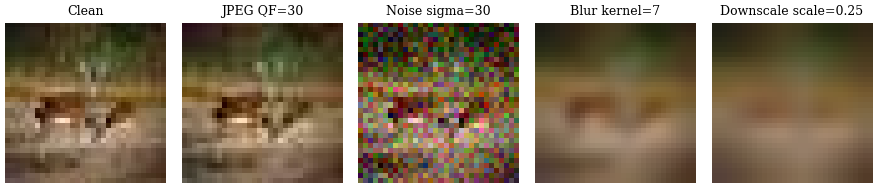

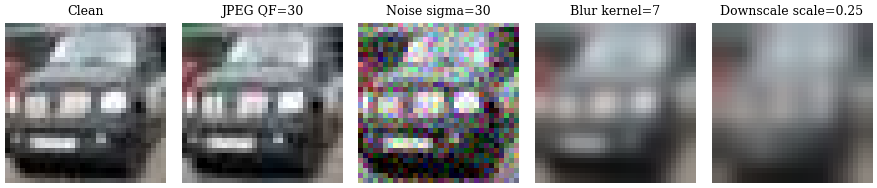

In [5]:
# ============================================================
# CELL 6: DEGRADATION FUNCTIONS
# ============================================================
# All four degradations operate on PIL images and return PIL images,
# so the downstream pipeline (transform -> ViT, edge-detection -> EBP)
# is the same for clean and degraded inputs.
#
# Each function is deterministic given its parameters (no random state).

def degrade_jpeg(pil_img, quality):
    """Re-encode as JPEG at the given quality factor (1-100)."""
    buf = io.BytesIO()
    pil_img.save(buf, format='JPEG', quality=int(quality))
    buf.seek(0)
    return Image.open(buf).convert('RGB').copy()

def degrade_noise(pil_img, sigma):
    """Add Gaussian noise N(0, sigma^2) in [0,255] pixel space."""
    arr = np.asarray(pil_img).astype(np.float32)
    rng = np.random.RandomState(0)        # deterministic noise per call
    noise = rng.normal(0, sigma, size=arr.shape)
    out = np.clip(arr + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(out)

def degrade_blur(pil_img, kernel):
    """Gaussian blur with given odd square kernel."""
    arr = np.asarray(pil_img)
    k = int(kernel)
    if k % 2 == 0:
        k += 1
    out = cv2.GaussianBlur(arr, (k, k), sigmaX=0)
    return Image.fromarray(out)

def degrade_downscale(pil_img, scale):
    """Downscale to `scale` of size, then upscale back to original."""
    w, h = pil_img.size
    nw, nh = max(1, int(w * scale)), max(1, int(h * scale))
    small = pil_img.resize((nw, nh), Image.BILINEAR)
    return small.resize((w, h), Image.BILINEAR)

DEGRADERS = {
    'JPEG'      : degrade_jpeg,
    'Noise'     : degrade_noise,
    'Blur'      : degrade_blur,
    'Downscale' : degrade_downscale,
}

# Quick visual sanity check: show clean + each degradation at the
# strongest level for one REAL and one FAKE image.
def _sample_one_of_each(imgs, lbls):
    idx_fake = int(np.where(lbls == FAKE_ID)[0][0])
    idx_real = int(np.where(lbls == REAL_ID)[0][0])
    return imgs[idx_fake], imgs[idx_real]

img_f, img_r = _sample_one_of_each(imgs_test, gt_test)

for name, img in [('FAKE', img_f), ('REAL', img_r)]:
    degraded = {}
    for dtype, conf in CONFIG['degradations'].items():
        # Pick the worst level for visual emphasis
        worst = conf['levels'][-1] if dtype != 'JPEG' else conf['levels'][-1]
        d = DEGRADERS[dtype](img, worst)
        degraded[f'{dtype} {conf["param_name"]}={worst}'] = d
    show_degradation_grid(
        img, degraded,
        save_path=os.path.join(CONFIG['output_dir'],
                               f'fig_degradation_grid_{name.lower()}.png'),
    )

In [6]:
# ============================================================
# CELL 7: RE-INFERENCE FUNCTIONS (ViT logits + EBP score)
# ============================================================
# Two helpers used inside the main evaluation loop:
#   - predict_vit_on_pil:  takes list of PIL images, returns
#                          (logits, P_FAKE, max_conf, argmax_pred)
#   - compute_ebp_on_pil:  takes list of PIL, returns scalar score S per image
#
# Both functions are pure: they do not modify any global state and
# do not depend on the calibration constants -- those come in later
# at the inference-mode application step.

# --- 7.1 EBP scoring (same Eq. 3-10 as Notebook 01 Cell 11) ---
def compute_ebp_score(pil_img,
                      ksize=3, sigma=0.0,
                      canny_low=100, canny_high=200,
                      eps=1e-6):
    """Edge-Based Processing score S per arXiv:2508.17877 Eq. 3-10.
       S = N_edges / (var(E1 - E2) + eps).
    """
    arr  = np.asarray(pil_img)
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    blur = cv2.GaussianBlur(gray, (ksize, ksize), sigma)
    E1   = cv2.Canny(gray, canny_low, canny_high)
    E2   = cv2.Canny(blur, canny_low, canny_high)
    D    = E1.astype(np.int16) - E2.astype(np.int16)
    n_edges = int(np.count_nonzero(E1))
    var_D   = float(np.var(D))
    return n_edges / (var_D + eps)

def compute_ebp_batch(pil_list):
    """Vectorized over a list of PIL images."""
    return np.array([compute_ebp_score(im) for im in pil_list],
                    dtype=np.float32)

# --- 7.2 ViT inference ---
@torch.no_grad()
def predict_vit_on_pil(pil_list, batch_size=64):
    """Pass PIL images through clean_transform then through the frozen
       ViT. Returns (logits, P_FAKE, conf, pred) -- all numpy arrays.
    """
    from scipy.special import softmax
    all_logits = []
    for i in range(0, len(pil_list), batch_size):
        batch_pils = pil_list[i:i+batch_size]
        # Stack tensors
        tensors = torch.stack([clean_transform(im) for im in batch_pils]).to(DEVICE)
        out = model(pixel_values=tensors)
        all_logits.append(out.logits.detach().cpu().numpy())
    logits = np.concatenate(all_logits, axis=0).astype(np.float32)
    probs  = softmax(logits, axis=1)
    pred   = logits.argmax(axis=1)
    pf     = probs[:, FAKE_ID]
    conf   = probs.max(axis=1)
    return logits, pf, conf, pred

# --- 7.3 Sanity check: reproduce Notebook 01 clean accuracy ---
print('Sanity check: re-running ViT on clean test set...')
_, vit_pf_clean, vit_conf_clean, vit_pred_clean = predict_vit_on_pil(
    imgs_test, batch_size=CONFIG['eval_batch'])
clean_acc = accuracy_score(gt_test, vit_pred_clean)
print(f'  Clean ViT accuracy (this notebook) : {clean_acc*100:.2f}%')
print(f'  Clean ViT accuracy (Notebook 01)   : '
      f'{accuracy_score(clean_gt_test, clean_vit_pred)*100:.2f}%')
# Re-inference under FP16 with eval_batch=64 can flip a small number of
# borderline predictions versus Notebook 01 (which used a different batch
# size). The test set itself is verified identical in Cell 5 (gt_test
# matches Notebook 01 bit-for-bit), so a 1-2 image difference here is
# benign inference non-determinism, NOT a split/preprocessing mismatch.
# We allow a small tolerance and only fail on a large discrepancy.
n_test    = len(clean_gt_test)
ref_acc   = accuracy_score(clean_gt_test, clean_vit_pred)
n_flipped = round(abs(clean_acc - ref_acc) * n_test)
assert n_flipped <= 3, (
    f'Clean accuracy differs from Notebook 01 by {n_flipped} images '
    f'({abs(clean_acc - ref_acc)*100:.2f}%). More than 3 images suggests '
    f'a real test split / preprocessing mismatch, not FP16 non-determinism.'
)
if n_flipped == 0:
    print('[OK] Reproduces Notebook 01 clean result bitwise.')
else:
    print(f'[OK] Within tolerance: {n_flipped} borderline image(s) flipped '
          f'vs Notebook 01 (FP16 / eval batch-size non-determinism).')

Sanity check: re-running ViT on clean test set...
  Clean ViT accuracy (this notebook) : 95.83%
  Clean ViT accuracy (Notebook 01)   : 95.83%
[OK] Reproduces Notebook 01 clean result bitwise.


In [7]:
# ============================================================
# CELL 8: APPLY 5 INFERENCE MODES UNDER A GIVEN DEGRADATION
# ============================================================
# This is the workhorse function. Given:
#   - degraded test images (a list of PILs)
#   - the same labels gt_test
#   - frozen calibrators (T_star, tau_star, scaler, clf)
# it returns a dict with predictions and metrics for all 5 modes.

def apply_all_modes(deg_imgs, gt, T_star, tau_star, scaler, clf,
                    fake_id=FAKE_ID, real_id=REAL_ID):
    """Run all 5 inference modes on a (possibly degraded) image batch.

    Returns a dict containing:
        results[mode_name] = {
            'pred'  : np.ndarray (N,) class predictions,
            'score' : np.ndarray (N,) ranking score for FAKE-positive,
            'metric': dict from format_metrics_dict(),
        }
    Plus 'ebp_score' and 'vit_conf' for diagnostics.
    """
    # 1. Re-run ViT
    _, vit_pf, vit_conf, vit_pred = predict_vit_on_pil(deg_imgs)

    # 2. Re-run EBP scoring on the degraded images
    ebp_score = compute_ebp_batch(deg_imgs)

    # 3. Mode 1 -- ViT only
    m_vit = format_metrics_dict(gt, vit_pred, vit_pf, pos_label=fake_id)

    # 4. Mode 2 -- EBP only (threshold from Notebook 01)
    ebp_pred = np.where(ebp_score >= T_star, fake_id, real_id)
    m_ebp = format_metrics_dict(gt, ebp_pred, ebp_score, pos_label=fake_id)

    # 5. Mode 3 -- Confidence-gated (tau from Notebook 01)
    gated_pred = vit_pred.copy()
    low = vit_conf < tau_star
    gated_pred[low] = ebp_pred[low]
    # Heuristic gated score for AUC (same as Notebook 01)
    ebp_norm = (ebp_score - ebp_score.min()) / \
               (ebp_score.max() - ebp_score.min() + 1e-9)
    gated_score = np.where(low, ebp_norm, vit_pf)
    m_gated = format_metrics_dict(gt, gated_pred, gated_score, pos_label=fake_id)

    # 6. Mode 4 -- LogReg fusion (frozen scaler + clf from Notebook 01)
    X = np.column_stack([vit_pf, np.log1p(ebp_score), vit_conf])
    X_s = scaler.transform(X)
    fusion_pf = clf.predict_proba(X_s)[:, 1]
    fusion_pred = np.where(fusion_pf >= 0.5, fake_id, real_id)
    m_fusion = format_metrics_dict(gt, fusion_pred, fusion_pf, pos_label=fake_id)

    return {
        'ViT only'         : {'pred': vit_pred,    'score': vit_pf,      'metric': m_vit},
        'EBP only'         : {'pred': ebp_pred,    'score': ebp_score,   'metric': m_ebp},
        'Confidence-gated' : {'pred': gated_pred,  'score': gated_score, 'metric': m_gated},
        'LogReg fusion'    : {'pred': fusion_pred, 'score': fusion_pf,   'metric': m_fusion},
        '_vit_conf'        : vit_conf,
        '_ebp_score'       : ebp_score,
    }

# Quick test on CLEAN to make sure everything works and matches N01.
clean_out = apply_all_modes(imgs_test, gt_test, T_star, tau_star, scaler, clf)
print('--- Sanity check: clean accuracies match Notebook 01? ---')
for mode in ['ViT only', 'EBP only', 'Confidence-gated', 'LogReg fusion']:
    print(f'  {mode:20s}: {clean_out[mode]["metric"]["Accuracy (%)"]:.2f}%')
# Notebook 01 reference accuracies, recomputed from its SAVED arrays
# (arrays.npz) so this line never goes stale if Notebook 01 is re-run.
_n01_ebp_pred = np.where(clean_test_scores >= T_star, FAKE_ID, REAL_ID)
_n01_gated    = clean_vit_pred.copy()
_n01_low      = clean_vit_conf_test < tau_star
_n01_gated[_n01_low] = _n01_ebp_pred[_n01_low]
_n01_Xs       = scaler.transform(np.column_stack(
    [clean_vit_pf_test, np.log1p(clean_test_scores), clean_vit_conf_test]))
_n01_fusion   = np.where(clf.predict_proba(_n01_Xs)[:, 1] >= 0.5, FAKE_ID, REAL_ID)
print('(Notebook 01 reference: '
      f'{accuracy_score(clean_gt_test, clean_vit_pred)*100:.2f} / '
      f'{accuracy_score(clean_gt_test, _n01_ebp_pred)*100:.2f} / '
      f'{accuracy_score(clean_gt_test, _n01_gated)*100:.2f} / '
      f'{accuracy_score(clean_gt_test, _n01_fusion)*100:.2f})')

--- Sanity check: clean accuracies match Notebook 01? ---
  ViT only            : 95.83%
  EBP only            : 52.00%
  Confidence-gated    : 95.42%
  LogReg fusion       : 95.83%
(Notebook 01 reference: 95.83 / 52.00 / 95.42 / 95.83)


In [8]:
# ============================================================
# CELL 9: MAIN LOOP -- evaluate every (degradation, level, mode)
# ============================================================
# Outer loop over (degradation_type, level), inner: apply 5 modes.
# Results stored in a long-format DataFrame for easy plotting.
# Includes the clean baseline (degradation=None, level=0).
#
# Expected runtime on Colab T4: ~45 minutes for the full 18-config grid.

records = []

def _record(deg_type, level, mode_name, m):
    """Append one row to the long-format result table."""
    records.append({
        'degradation' : deg_type,
        'level'       : level,
        'mode'        : mode_name,
        'Accuracy (%)': m['Accuracy (%)'],
        'F1 (%)'      : m['F1-Score (%)'],
        'Precision (%)': m['Precision (%)'],
        'Recall (%)'  : m['Recall (%)'],
        'AUC-ROC (%)' : m.get('AUC-ROC (%)', np.nan),
        'PR-AUC (%)'  : m.get('PR-AUC (%)',  np.nan),
    })

# Clean baseline
for mode in ['ViT only', 'EBP only', 'Confidence-gated', 'LogReg fusion']:
    _record('Clean', 0, mode, clean_out[mode]['metric'])

# Store full per-image results for the most-degraded level of each
# degradation, so we can plot ROC/heatmaps later.
worst_case_outs = {}     # key: degradation_type, val: output dict

# Track all degradation evaluations for the heatmap and confidence analysis
all_outs = {}            # key: (deg_type, level), val: output dict
all_outs['Clean', 0] = clean_out

for deg_type, conf in CONFIG['degradations'].items():
    print(f'\n--- Degradation: {deg_type} ---')
    degrade_fn = DEGRADERS[deg_type]
    for level in tqdm(conf['levels'], desc=deg_type):
        # Apply degradation to ALL test images
        deg_imgs = [degrade_fn(im, level) for im in imgs_test]

        # Run all 5 modes (1-4 plus diagnostic; we omit Mode 0 leak here
        # because the diagnostic value of the leak is documented in
        # Notebook 01 -- it does not need to be repeated for every
        # degradation level).
        out = apply_all_modes(deg_imgs, gt_test, T_star, tau_star, scaler, clf)
        all_outs[(deg_type, level)] = out

        # Track worst case (last level) per degradation for later
        if level == conf['levels'][-1]:
            worst_case_outs[deg_type] = (deg_imgs, out)

        for mode in ['ViT only', 'EBP only', 'Confidence-gated', 'LogReg fusion']:
            _record(deg_type, level, mode, out[mode]['metric'])

        # Free degraded images list
        del deg_imgs
        gc.collect()

result_df = pd.DataFrame(records)
print('\n[OK] Main loop complete.')
print(f'   {len(result_df)} rows in result table.')
print(f'   Saving to {CONFIG["output_dir"]}/table_robustness_raw.csv')
save_results_csv(result_df,
                 os.path.join(CONFIG['output_dir'], 'table_robustness_raw.csv'))


--- Degradation: JPEG ---


JPEG:   0%|          | 0/4 [00:00<?, ?it/s]


--- Degradation: Noise ---


Noise:   0%|          | 0/4 [00:00<?, ?it/s]


--- Degradation: Blur ---


Blur:   0%|          | 0/3 [00:00<?, ?it/s]


--- Degradation: Downscale ---


Downscale:   0%|          | 0/3 [00:00<?, ?it/s]


[OK] Main loop complete.
   60 rows in result table.
   Saving to /content/outputs_nb02/table_robustness_raw.csv
[OK] Saved /content/outputs_nb02/table_robustness_raw.csv and /content/outputs_nb02/table_robustness_raw.md


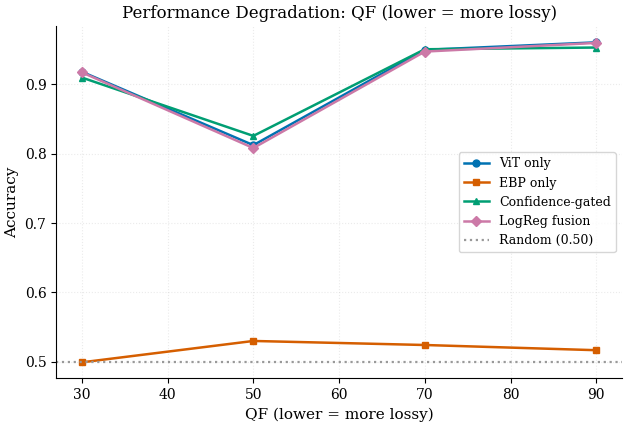

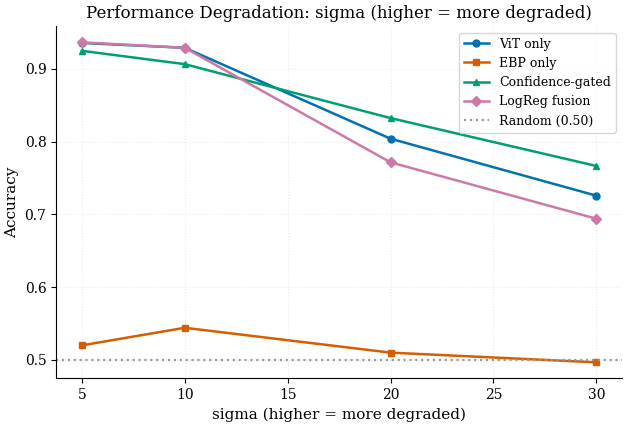

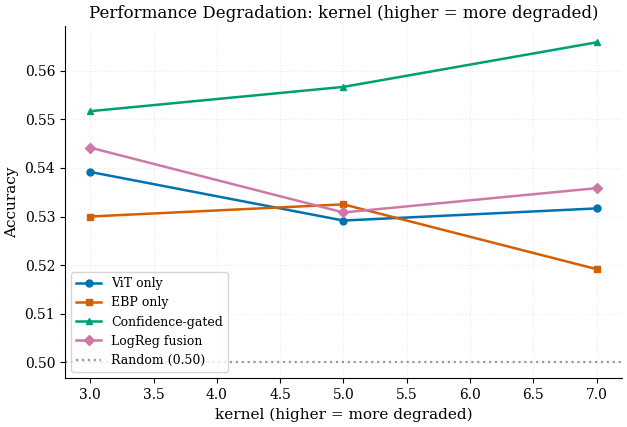

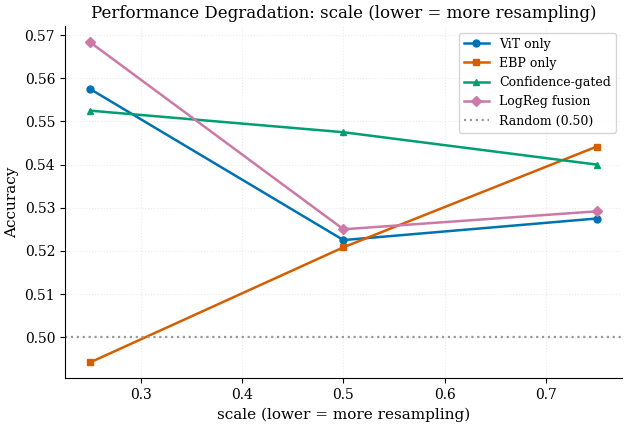

In [9]:
# ============================================================
# CELL 10: PERFORMANCE DEGRADATION CURVES (one per degradation)
# ============================================================
# Reproduces Hendrycks 2019 Figure 1 style: x-axis = severity,
# y-axis = accuracy, one line per inference mode.
# Important: x-axis ordering depends on degradation type. For JPEG QF,
# higher = better quality, so we plot in DECREASING QF order. For
# noise sigma / blur kernel / 1-downscale, higher = worse, plot ASC.

mode_order  = ['ViT only', 'EBP only', 'Confidence-gated', 'LogReg fusion']
mode_colors = [PALETTE['real'], PALETTE['fake'], PALETTE['highlight'],
               PALETTE['accent']]
mode_color_map = dict(zip(mode_order, mode_colors))

# Helper: x-axis label and direction per degradation
def xaxis_for(deg_type):
    param = CONFIG['degradations'][deg_type]['param_name']
    if deg_type == 'JPEG':
        return f'{param} (lower = more lossy)'
    elif deg_type == 'Downscale':
        return f'{param} (lower = more resampling)'
    else:
        return f'{param} (higher = more degraded)'

for deg_type in CONFIG['degradations']:
    sub = result_df[result_df['degradation'] == deg_type].copy()
    levels = CONFIG['degradations'][deg_type]['levels']
    # For JPEG and Downscale, larger param = LESS degraded, so we
    # display them in natural order; visually the user can read the
    # axis labels which explicitly say "lower = more lossy".

    series = {}
    for mode in mode_order:
        s = sub[sub['mode'] == mode].set_index('level').loc[levels]
        series[mode] = s['Accuracy (%)'].values / 100.0  # 0-1 scale

    plot_degradation_curve(
        condition_name=xaxis_for(deg_type),
        levels=levels,
        series=series,
        ylabel='Accuracy',
        y_random=0.5,
        save_path=os.path.join(
            CONFIG['output_dir'],
            f'fig_degradation_curve_{deg_type.lower()}.png'),
    )

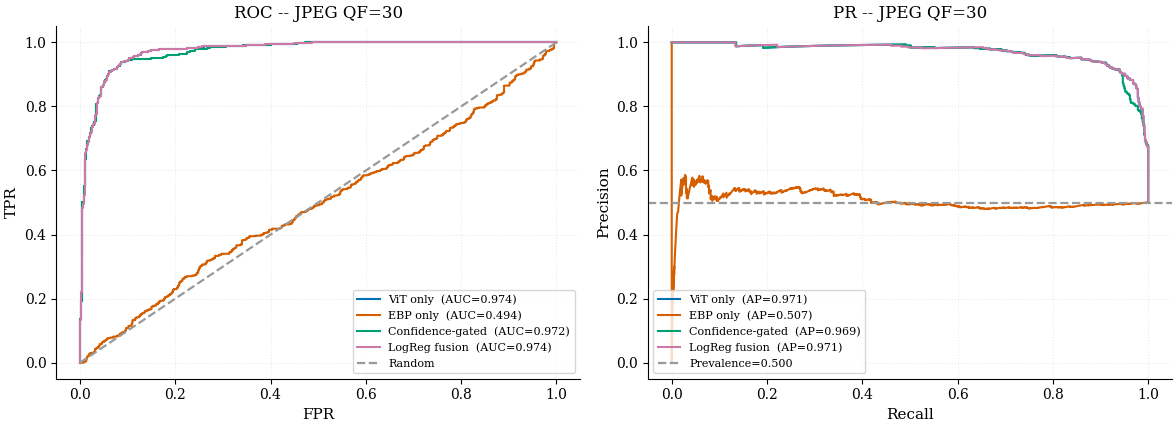

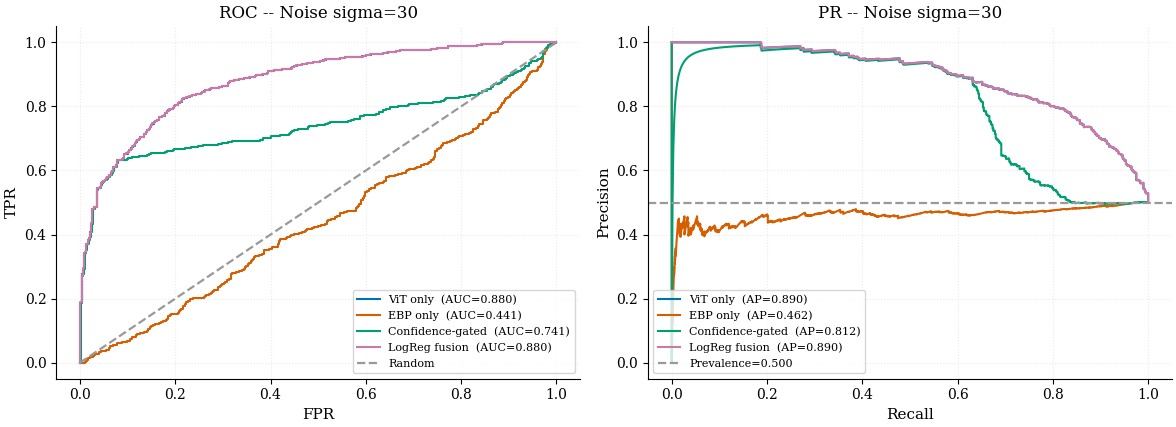

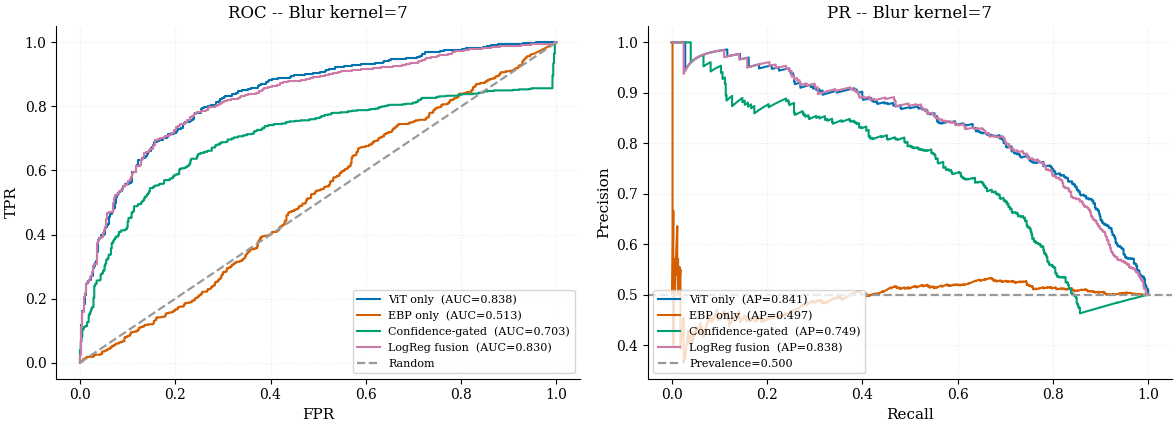

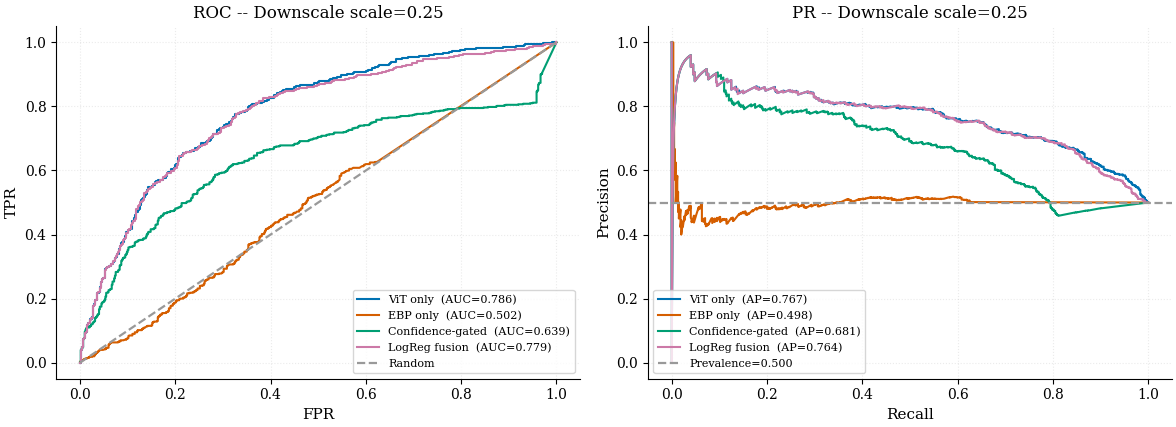

In [10]:
# ============================================================
# CELL 11: WORST-CASE ROC + PR  (all modes, all degradations)
# ============================================================
# For each degradation at its WORST level, draw ROC and PR curves to
# visualize whether AUC ordering changes from the clean case.

from sklearn.metrics import roc_curve, auc, precision_recall_curve

for deg_type, (deg_imgs, out) in worst_case_outs.items():
    worst_level = CONFIG['degradations'][deg_type]['levels'][-1]
    param = CONFIG['degradations'][deg_type]['param_name']

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    for mode in mode_order:
        score = out[mode]['score']
        # ROC
        fpr, tpr, _ = roc_curve(gt_test, score, pos_label=FAKE_ID)
        a_roc = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, color=mode_color_map[mode], lw=1.5,
                     label=f'{mode}  (AUC={a_roc:.3f})')
        # PR
        p, r, _ = precision_recall_curve(gt_test, score, pos_label=FAKE_ID)
        a_pr = average_precision_score(gt_test == FAKE_ID, score)
        axes[1].plot(r, p, color=mode_color_map[mode], lw=1.5,
                     label=f'{mode}  (AP={a_pr:.3f})')

    axes[0].plot([0, 1], [0, 1], '--', color=PALETTE['neutral'], label='Random')
    axes[0].set(xlabel='FPR', ylabel='TPR',
                title=f'ROC -- {deg_type} {param}={worst_level}')
    axes[0].legend(fontsize=8, loc='lower right')

    prev = float(np.mean(gt_test == FAKE_ID))
    axes[1].axhline(prev, ls='--', color=PALETTE['neutral'],
                    label=f'Prevalence={prev:.3f}')
    axes[1].set(xlabel='Recall', ylabel='Precision',
                title=f'PR -- {deg_type} {param}={worst_level}')
    axes[1].legend(fontsize=8, loc='lower left')

    fig.tight_layout()
    save_figure(fig, os.path.join(
        CONFIG['output_dir'],
        f'fig_roc_pr_worst_{deg_type.lower()}.png'))
    plt.show()

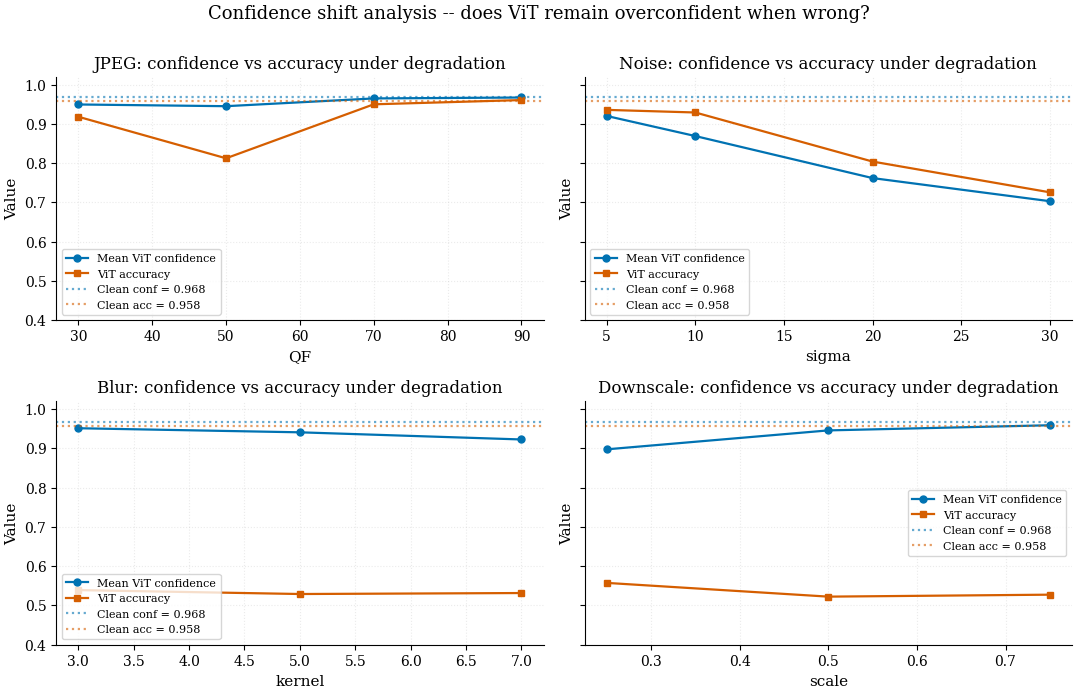

In [11]:
# ============================================================
# CELL 12: CONFIDENCE SHIFT ANALYSIS
# ============================================================
# Key diagnostic: does ViT confidence actually drop under degradation?
# If yes -- confidence-gating MIGHT work. If no -- ViT remains
# overconfident even when wrong, and gating cannot help.
#
# Plot mean ViT confidence as a function of degradation level for
# each degradation type, alongside accuracy on the same axis.

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)

for ax, (deg_type, conf) in zip(axes.flat, CONFIG['degradations'].items()):
    levels = conf['levels']
    mean_confs = []
    accs       = []
    for lv in levels:
        out = all_outs[(deg_type, lv)]
        mean_confs.append(out['_vit_conf'].mean())
        accs.append(out['ViT only']['metric']['Accuracy (%)'] / 100.0)

    # Add clean baseline
    clean_conf = clean_out['_vit_conf'].mean()
    clean_acc  = clean_out['ViT only']['metric']['Accuracy (%)'] / 100.0

    ax.plot(levels, mean_confs, '-o', color=PALETTE['real'],
            label='Mean ViT confidence')
    ax.plot(levels, accs,       '-s', color=PALETTE['fake'],
            label='ViT accuracy')
    ax.axhline(clean_conf, ls=':', color=PALETTE['real'], alpha=0.6,
               label=f'Clean conf = {clean_conf:.3f}')
    ax.axhline(clean_acc,  ls=':', color=PALETTE['fake'], alpha=0.6,
               label=f'Clean acc = {clean_acc:.3f}')

    ax.set_xlabel(f"{conf['param_name']}")
    ax.set_ylabel('Value')
    ax.set_title(f'{deg_type}: confidence vs accuracy under degradation')
    ax.legend(fontsize=8, loc='lower left' if deg_type != 'Downscale' else 'best')
    ax.set_ylim(0.4, 1.02)

fig.suptitle('Confidence shift analysis -- does ViT remain overconfident '
             'when wrong?', y=1.00)
fig.tight_layout()
save_figure(fig, os.path.join(CONFIG['output_dir'],
                              'fig_confidence_shift.png'))
plt.show()

In [12]:
# ============================================================
# CELL 13: SECONDARY ANALYSIS -- PER-DEGRADATION CALIBRATION
# ============================================================
# This is the "upper bound" reported alongside the frozen main results.
#
# Question: if we KNEW the degradation type in advance, and could
# re-calibrate tau_star and the LogReg fusion on a held-out validation
# set drawn from the SAME degradation, would gating/fusion improve?
#
# Method:
#   1. Take clean validation set arrays already computed in Notebook 01.
#   2. Apply each degradation to a validation set of equal size.
#      (We need raw validation images -- reload from HuggingFace using
#       the same balanced subset rule.)
#   3. Recompute val ViT predictions / EBP scores under degradation.
#   4. Re-fit tau and LogReg on those degraded val features.
#   5. Apply to the corresponding degraded test set.
#
# For brevity we run this ONLY at the worst level per degradation
# (5 configs: Clean + 4 worst). Per-level calibration would multiply
# runtime by 5.

# Validation images already loaded in Cell 5 (same split as Notebook 01).
# Just alias for clarity.
gt_val = gt_val_local
print(f'Validation subset (from Cell 5): {len(imgs_val)} images')

def recalibrate_on_degraded_val(deg_type, level, deg_imgs_test):
    """Re-fit tau_star and LogReg on validation degraded at the same
    level, then return predictions on the already-degraded test set.

    Returns a dict {mode_name: metric_dict} for the recalibrated modes.
    """
    degrade_fn = DEGRADERS[deg_type]
    deg_imgs_val = [degrade_fn(im, level) for im in imgs_val]

    # Re-infer val features
    _, vpf_val, vconf_val, vpred_val = predict_vit_on_pil(deg_imgs_val)
    ebp_val = compute_ebp_batch(deg_imgs_val)

    # Re-fit tau: maximize val F1 (FAKE positive) over a grid
    ebp_pred_val = np.where(ebp_val >= T_star, FAKE_ID, REAL_ID)
    tau_grid = np.linspace(0.50, 1.00, 51)
    f1s = []
    for tau in tau_grid:
        gp = vpred_val.copy()
        low = vconf_val < tau
        gp[low] = ebp_pred_val[low]
        f1s.append(f1_score(gt_val, gp, pos_label=FAKE_ID, zero_division=0))
    tau_new = float(tau_grid[int(np.argmax(f1s))])

    # Re-fit LogReg on degraded val
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    X_val = np.column_stack([vpf_val, np.log1p(ebp_val), vconf_val])
    scaler_new = StandardScaler().fit(X_val)
    clf_new = LogisticRegression(class_weight='balanced', max_iter=500,
                                  random_state=SEED, solver='lbfgs')
    clf_new.fit(scaler_new.transform(X_val),
                (gt_val == FAKE_ID).astype(int))

    # Apply recalibrated calibrators to the already-degraded test images
    out = apply_all_modes(deg_imgs_test, gt_test,
                          T_star, tau_new, scaler_new, clf_new)
    return {mode: out[mode]['metric']
            for mode in ['ViT only', 'EBP only',
                         'Confidence-gated', 'LogReg fusion']}, tau_new

# Run recalibration for each degradation at its worst level
recal_records = []
for deg_type in CONFIG['degradations']:
    worst_level = CONFIG['degradations'][deg_type]['levels'][-1]
    print(f'\nRecalibrating for {deg_type} (worst level = {worst_level})...')
    deg_imgs_test_worst, _ = worst_case_outs[deg_type]
    recal_metrics, tau_new = recalibrate_on_degraded_val(
        deg_type, worst_level, deg_imgs_test_worst)
    for mode in ['ViT only', 'EBP only', 'Confidence-gated', 'LogReg fusion']:
        m = recal_metrics[mode]
        recal_records.append({
            'degradation' : deg_type,
            'level'       : worst_level,
            'mode'        : mode,
            'Accuracy (%)': m['Accuracy (%)'],
            'F1 (%)'      : m['F1-Score (%)'],
            'AUC-ROC (%)' : m.get('AUC-ROC (%)', np.nan),
            'tau_new'     : tau_new,
        })

recal_df = pd.DataFrame(recal_records)
print('\n--- Per-degradation calibration (upper bound) ---')
print(recal_df.to_string(index=False, float_format=lambda x: f'{x:7.2f}'))
save_results_csv(recal_df,
                 os.path.join(CONFIG['output_dir'],
                              'table_robustness_recalibrated.csv'))

Validation subset (from Cell 5): 1200 images

Recalibrating for JPEG (worst level = 30)...

Recalibrating for Noise (worst level = 30)...

Recalibrating for Blur (worst level = 7)...

Recalibrating for Downscale (worst level = 0.25)...

--- Per-degradation calibration (upper bound) ---
degradation   level             mode  Accuracy (%)  F1 (%)  AUC-ROC (%)  tau_new
       JPEG   30.00         ViT only         91.83   92.22        97.44     0.86
       JPEG   30.00         EBP only         49.92   47.05        49.36     0.86
       JPEG   30.00 Confidence-gated         90.50   90.88        97.00     0.86
       JPEG   30.00    LogReg fusion         92.33   92.50        96.70     0.86
      Noise   30.00         ViT only         72.58   77.36        88.01     0.57
      Noise   30.00         EBP only         49.67    2.89        44.14     0.57
      Noise   30.00 Confidence-gated         77.17   79.61        85.70     0.57
      Noise   30.00    LogReg fusion         80.50   80.53       

In [13]:
# ============================================================
# CELL 14: FROZEN vs RECALIBRATED COMPARISON TABLE
# ============================================================
# Final headline table for the thesis: for each (degradation_worst,
# mode) we show frozen accuracy vs recalibrated accuracy.

comp_rows = []
for deg_type in CONFIG['degradations']:
    worst_level = CONFIG['degradations'][deg_type]['levels'][-1]
    for mode in ['ViT only', 'EBP only', 'Confidence-gated', 'LogReg fusion']:
        frozen = result_df[
            (result_df['degradation'] == deg_type) &
            (result_df['level'] == worst_level) &
            (result_df['mode'] == mode)]['Accuracy (%)'].iloc[0]
        recal  = recal_df[
            (recal_df['degradation'] == deg_type) &
            (recal_df['mode'] == mode)]['Accuracy (%)'].iloc[0]
        comp_rows.append({
            'Degradation' : f'{deg_type} (worst)',
            'Mode'        : mode,
            'Frozen (%)'  : frozen,
            'Recalibrated (%)' : recal,
            'Gap (pp)'    : recal - frozen,
        })
comp_df = pd.DataFrame(comp_rows)

print('\n' + '=' * 80)
print(' HEADLINE: frozen vs per-degradation calibration')
print('=' * 80)
print(comp_df.to_string(index=False, float_format=lambda x: f'{x:7.2f}'))
save_results_csv(comp_df,
                 os.path.join(CONFIG['output_dir'],
                              'table_frozen_vs_recalibrated.csv'))


 HEADLINE: frozen vs per-degradation calibration
      Degradation             Mode  Frozen (%)  Recalibrated (%)  Gap (pp)
     JPEG (worst)         ViT only       91.83             91.83      0.00
     JPEG (worst)         EBP only       49.92             49.92      0.00
     JPEG (worst) Confidence-gated       91.00             90.50     -0.50
     JPEG (worst)    LogReg fusion       91.75             92.33      0.58
    Noise (worst)         ViT only       72.58             72.58      0.00
    Noise (worst)         EBP only       49.67             49.67      0.00
    Noise (worst) Confidence-gated       76.67             77.17      0.50
    Noise (worst)    LogReg fusion       69.42             80.50     11.08
     Blur (worst)         ViT only       53.17             53.17      0.00
     Blur (worst)         EBP only       51.92             51.92      0.00
     Blur (worst) Confidence-gated       56.58             71.75     15.17
     Blur (worst)    LogReg fusion       53.58    

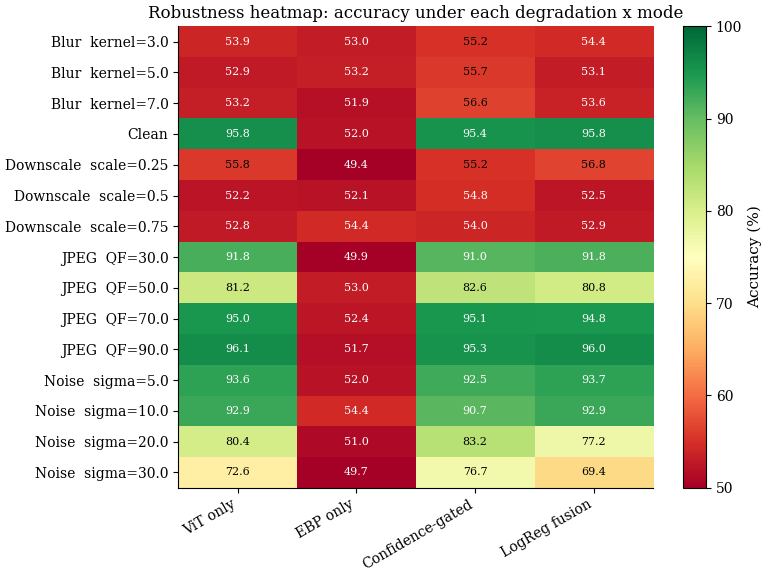

In [14]:
# ============================================================
# CELL 15: HEATMAP -- ACCURACY x MODE x DEGRADATION
# ============================================================
# Compact summary visualization. Rows = (degradation, level), cols = mode.
# Cell color = accuracy. Inspired by Hendrycks 2019 Table 2.

heatmap_df = result_df.pivot_table(
    index=['degradation', 'level'],
    columns='mode',
    values='Accuracy (%)',
)[mode_order]   # ensure column order

fig, ax = plt.subplots(figsize=(8, max(6, 0.35 * len(heatmap_df))))
im = ax.imshow(heatmap_df.values, aspect='auto', cmap='RdYlGn',
               vmin=50, vmax=100)
fig.colorbar(im, ax=ax, label='Accuracy (%)')
ax.set_xticks(range(len(heatmap_df.columns)))
ax.set_xticklabels(heatmap_df.columns, rotation=30, ha='right')
ax.set_yticks(range(len(heatmap_df.index)))
ax.set_yticklabels([f'{d}  {p}={lv}'
                    if d != 'Clean' else 'Clean'
                    for (d, lv), p in zip(
                        heatmap_df.index,
                        [CONFIG['degradations'].get(d, {}).get('param_name', '')
                         for (d, lv) in heatmap_df.index])])
# Annotate cells
for i in range(heatmap_df.shape[0]):
    for j in range(heatmap_df.shape[1]):
        v = heatmap_df.values[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center',
                color='black' if 55 < v < 90 else 'white', fontsize=8)
ax.set_title('Robustness heatmap: accuracy under each degradation x mode')
ax.grid(False)
fig.tight_layout()
save_figure(fig, os.path.join(CONFIG['output_dir'],
                              'fig_robustness_heatmap.png'))
plt.show()

In [15]:
# ============================================================
# CELL 16: SAVE ARTIFACTS TO DRIVE
# ============================================================
# Backup result tables and figures so the thesis writing phase can
# pull from Drive directly. Also save the long-format dataframe as
# a .pkl so Notebook 03 (XAI) can cross-reference per-image
# predictions if needed.

# Save the per-degradation worst-case outputs (raw arrays) so the XAI
# notebook can reuse the same degraded images and predictions.
np.savez(os.path.join(CONFIG['output_dir'], 'worst_case_outputs.npz'),
         **{
             f'{deg_type}_pred_{mode.replace(" ", "_")}'.lower():
                 worst_case_outs[deg_type][1][mode]['pred']
             for deg_type in worst_case_outs
             for mode in mode_order
         },
         gt_test=gt_test,
         T_star=np.float32(T_star),
         tau_star=np.float32(tau_star),
        )

# Save the result dataframes as pickle for fidelity
result_df.to_pickle(os.path.join(CONFIG['output_dir'], 'result_df.pkl'))
recal_df.to_pickle(os.path.join(CONFIG['output_dir'], 'recal_df.pkl'))
comp_df.to_pickle(os.path.join(CONFIG['output_dir'], 'comp_df.pkl'))

# Backup everything to Drive
backup_outputs_to_drive(
    output_dir=CONFIG['output_dir'],
    drive_dir=CONFIG['drive_backup'],
)

print(f'\n[OK] Notebook 02 complete. All artifacts at:')
print(f'     {CONFIG["drive_backup"]}')
print('     Notebook 03 (XAI) can load these to inspect per-image')
print('     prediction differences between clean and degraded.')

[OK] Backed up 31 files -> /content/drive/MyDrive/luanvan_thac_si/notebook02_artifacts

[OK] Notebook 02 complete. All artifacts at:
     /content/drive/MyDrive/luanvan_thac_si/notebook02_artifacts
     Notebook 03 (XAI) can load these to inspect per-image
     prediction differences between clean and degraded.


# Summary & interpretation

**Expected outcomes (interpretation guide for the thesis):**

1. **Degradation curves**: All four modes likely decline together
   under each degradation. The thesis should report the slope of
   decline as a robustness metric, in addition to absolute accuracy.

2. **EBP-only stays near random**: Mode 2 will stay around 50% on all
   degradations -- EBP carries no signal under any condition. This is
   consistent evidence that handcrafted Canny edge variance is not a
   discriminative feature for diffusion-generated images at this
   resolution.

3. **Confidence shift plot**: This is the most diagnostic figure. If
   ViT confidence drops sharply under degradation (e.g. mean conf
   falls from 0.97 to 0.7 under heavy noise), then there IS room for
   gating to help -- IF EBP could provide signal in that regime. If
   confidence stays high even when accuracy drops, ViT remains
   overconfident-when-wrong and gating is fundamentally limited.

4. **Frozen vs recalibrated gap**: If recalibrated accuracy is
   substantially higher than frozen for Modes 3/4, then deployment
   realism (frozen) hurts; the thesis can argue that adaptive
   calibration is a useful extension. If the gap is small, frozen
   calibration is fine for production deployment.

**Suggested thesis Chapter 4 narrative**:

> "We evaluate robustness across four standard image degradations at
> five severity levels each (Hendrycks & Dietterich 2019). For each
> configuration, all five inference modes are re-evaluated with
> calibrators frozen from clean-validation training (Section 4.X).
> Figure 4.X shows the Performance Degradation Curves; Table 4.X
> summarizes the worst-case accuracy per degradation. All modes
> decline at similar rates, with no significant advantage for EBP
> fusion under degradation -- consistent with the clean-condition
> finding that the EBP score lacks discriminative signal. This
> motivates the learnable edge filter introduced in Notebook 04
> (Chapter X)."